In [22]:
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve
from sklearn.dummy import DummyClassifier
from sklearn.metrics import PrecisionRecallDisplay

In [2]:
df = pd.read_csv('../data/processed/housing_data_engineered.csv', parse_dates=['date'])
print("Data shape:", df.shape)
print("Columns:", df.columns.tolist())

Data shape: (262780, 64)
Columns: ['date', 'median_sale_price', 'median_list_price', 'median_ppsf', 'median_list_ppsf', 'homes_sold', 'pending_sales', 'new_listings', 'inventory', 'median_dom', 'avg_sale_to_list', 'sold_above_list', 'off_market_in_two_weeks', 'city', 'zipcode', 'year', 'bank', 'bus', 'hospital', 'mall', 'park', 'restaurant', 'school', 'station', 'supermarket', 'Total Population', 'Median Age', 'Per Capita Income', 'Total Families Below Poverty', 'Total Housing Units', 'Median Rent', 'Median Home Value', 'Total Labor Force', 'Unemployed Population', 'Total School Age Population', 'Total School Enrollment', 'Median Commute Time', 'price', 'city_full', 'month', 'quarter', 'list_sale_gap', 'ppsf_gap', 'future_price_6m', 'price_change_6m_pct', 'downturn_risk', 'price_ma_3m', 'price_ma_6m', 'price_ma_12m', 'price_mom', 'price_volatility_3m', 'price_volatility_6m', 'stl_momentum', 'inventory_turnover', 'dom_trend', 'price_lag_3m', 'inventory_lag_3m', 'sales_lag_3m', 'price_la

In [3]:
#train on 2013-2021, test on 2022-2023
train = df[df['year'] <= 2021].copy()
test = df[df['year'] >= 2022].copy()

print(f"Train size: {train.shape} 2013-2021")
print(f"Test size: {test.shape} 2022-2023")
print(f"Train downturn rate: {train['downturn_risk'].mean():.4f}")
print(f"Test downturn rate: {test['downturn_risk'].mean():.4f}")

Train size: (224096, 64) 2013-2021
Test size: (38684, 64) 2022-2023
Train downturn rate: 0.1336
Test downturn rate: 0.1674


In [4]:
drop_cols = ['date', 'future_price_6m', 'price_change_6m_pct', 'downturn_risk']

x_train = train.drop(columns=drop_cols)
y_train = train['downturn_risk']
x_test = test.drop(columns=drop_cols)
y_test = test['downturn_risk']

#one‑hot encoded categorical variables (city, city_full)
categorical_cols = ['city', 'city_full']
x_train = pd.get_dummies(x_train, columns=categorical_cols, drop_first=True)
x_test = pd.get_dummies(x_test, columns=categorical_cols, drop_first=True)
x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

print(f"Features after encoding: {x_train.shape[1]}")

Features after encoding: 78


In [13]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=6740,
    n_jobs=-1
)

#using balanced based on stack overflowadvice, better handles 13% downturn
#also didnt scale but it doesn't really matter for random forest
rf.fit(x_train, y_train)
y_pred_prob = rf.predict_proba(x_test)[:, 1]

In [14]:
y_pred = (y_pred_prob >= 0.5).astype(int)

print("Random Forest Performance with threshold=0.5")
print(classification_report(y_test, y_pred, target_names=['No Downturn', 'Downturn']))
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"ROC‑AUC Score: {roc_auc_score(y_test, y_pred_prob):.4f}")

Random Forest Performance with threshold=0.5
              precision    recall  f1-score   support

 No Downturn       0.89      0.87      0.88     86230
    Downturn       0.45      0.50      0.48     17832

    accuracy                           0.81    104062
   macro avg       0.67      0.69      0.68    104062
weighted avg       0.82      0.81      0.81    104062

Confusion Matrix:
[[75398 10832]
 [ 8861  8971]]
ROC‑AUC Score: 0.8024


In [15]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(x_train, y_train)
y_dummy_pred = dummy.predict(x_test)

print("Baseline ('No Downturn')")
print(classification_report(y_test, y_dummy_pred))

Baseline ('No Downturn')
              precision    recall  f1-score   support

           0       0.83      1.00      0.91     86230
           1       0.00      0.00      0.00     17832

    accuracy                           0.83    104062
   macro avg       0.41      0.50      0.45    104062
weighted avg       0.69      0.83      0.75    104062



C:\Users\diyam\Documents\miniconda\lib\site-packages\sklearn\metrics\_classification.py:1334: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\diyam\Documents\miniconda\lib\site-packages\sklearn\metrics\_classification.py:1334: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\diyam\Documents\miniconda\lib\site-packages\sklearn\metrics\_classification.py:1334: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Top 20 Most Important Features for Predicting Downturns
                     feature  importance
               list_sale_gap    0.162399
         price_volatility_6m    0.076918
                sales_lag_6m    0.055056
                   price_mom    0.043780
                sales_lag_3m    0.031468
               sales_lag_12m    0.031077
         price_volatility_3m    0.029311
               pending_sales    0.029161
                       month    0.027672
Total Families Below Poverty    0.025434
           median_sale_price    0.020400
                     quarter    0.018646
                     zipcode    0.017459
 Total School Age Population    0.017057
          inventory_turnover    0.016628
           Total Labor Force    0.015854
            Total Population    0.014957
     Total School Enrollment    0.014293
                new_listings    0.014252
                price_lag_6m    0.014198


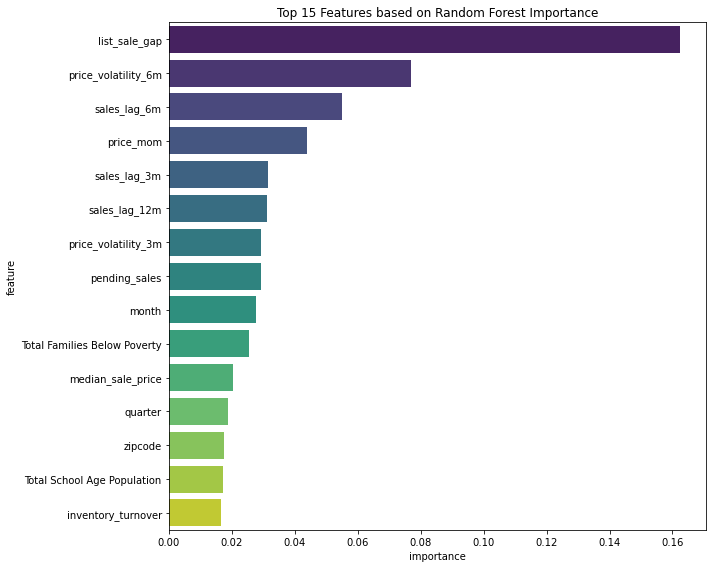

In [16]:
#feature importance
feature_names = x_train.columns.tolist()
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("Top 20 Most Important Features for Predicting Downturns")
print(importance_df.head(20).to_string(index=False))

#plotting the top 15
plt.figure(figsize=(10, 8))
top15 = importance_df.head(15)
sns.barplot(data=top15, x='importance', y='feature', palette='viridis')
plt.title('Top 15 Features based on Random Forest Importance')
plt.tight_layout()
plt.show()

In [17]:
# remember recall is obv = true pos/all pos
# and precision is true po/pred pos
# for the context of this project, having a higher recall to prevent 
# false positives is a smarter decision
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_prob)

for target_recall in [0.6, 0.7, 0.8]:
    # find closest threshold
    idx = numpy.argmin(numpy.abs(recalls - target_recall))
    print(f"Recall ≈ {recalls[idx]:.3f} at threshold = {thresholds[idx]:.3f}")
    print(f"  Precision at that threshold: {precisions[idx]:.3f}")

# including the early-warning threshold of 0.342 in report, 
# to show how the model can be tuned for a higher recall
# using 0.5 threshold as default 

Recall ≈ 0.600 at threshold = 0.420
  Precision at that threshold: 0.406
Recall ≈ 0.700 at threshold = 0.342
  Precision at that threshold: 0.364
Recall ≈ 0.800 at threshold = 0.260
  Precision at that threshold: 0.318


In [18]:
# trying to adjust the threshold to improve recall
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_prob)

target_recall = 0.5
idx = numpy.argmin(numpy.abs(recalls[:-1] - target_recall))
best_thresh = thresholds[idx]
print(f"threshold to achieve recall ~{target_recall}: {best_thresh:.3f}")

y_pred_adjusted = (y_pred_prob >= best_thresh).astype(int)
print(f"\nPerformance with adjusted threshold ({best_thresh:.3f}):")
print(classification_report(y_test, y_pred_adjusted))

threshold to achieve recall ~0.5: 0.503

Performance with adjusted threshold (0.503):
              precision    recall  f1-score   support

           0       0.89      0.88      0.89     86230
           1       0.46      0.50      0.48     17832

    accuracy                           0.81    104062
   macro avg       0.67      0.69      0.68    104062
weighted avg       0.82      0.81      0.82    104062



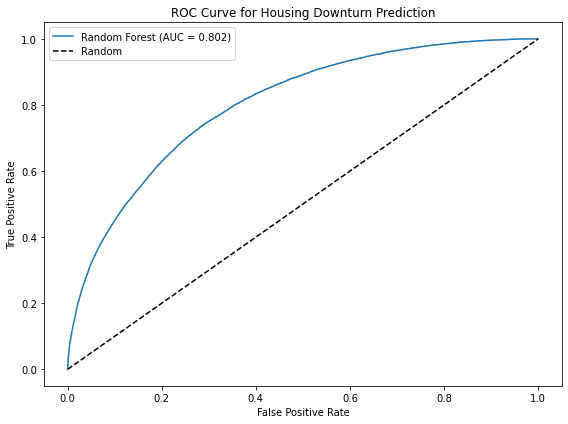

In [19]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Housing Downturn Prediction')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
results = test[['date', 'city', 'zipcode']].copy()
results['actual_downturn'] = y_test.values
results['probability'] = y_pred_prob

threshold = 0.342
results['predicted_downturn'] = (y_pred_prob >= threshold).astype(int)

import os
os.makedirs('../data/result', exist_ok=True)
results.to_csv('../data/result/rf_predictions.csv', index=False)
print("Saved predictions to ../data/result/rf_predictions.csv")
print(results.head())

Saved predictions to ../data/result/rf_predictions.csv
          date city  zipcode  actual_downturn  probability  predicted_downturn
106 2022-01-31  BOS     1431                0     0.400125                   1
107 2022-02-28  BOS     1431                0     0.418484                   1
108 2022-03-31  BOS     1431                0     0.316942                   0
109 2022-04-30  BOS     1431                0     0.414855                   1
110 2022-05-31  BOS     1431                1     0.598950                   1


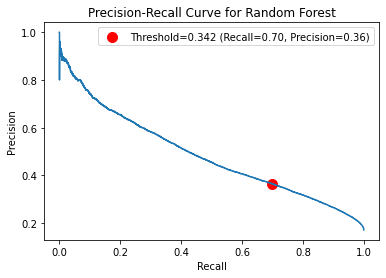

In [24]:
# realizing i forgot to even plot the precision recall curve. my bad!!

disp = PrecisionRecallDisplay(precision=precisions, recall=recalls)
disp.plot()
plt.title('Precision-Recall Curve for Random Forest')
plt.xlabel('Recall')
plt.ylabel('Precision')

target_thresh = 0.342
idx = (numpy.abs(thresholds - target_thresh)).argmin()
plt.scatter(recalls[idx], precisions[idx], color='red', s=100, 
            label=f'Threshold={target_thresh} (Recall={recalls[idx]:.2f}, Precision={precisions[idx]:.2f})')
plt.legend()
plt.show()
